# Hands-On Practice: ANOVA & Monte Carlo Simulation
This notebook has two sections:
- **Part 1:** One-Way ANOVA — Testing if sales differ across 4 store regions
- **Part 2:** Monte Carlo Simulation — Estimating profit probability for a new product launch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)
print('Libraries loaded successfully.')

Libraries loaded successfully.


---
# PART 1: One-Way ANOVA
## Business Problem
You are a Data Scientist at a retail company. You have 4 store regions (North, South, East, West). Your Head of Sales asks: **'Are the average weekly sales significantly different across our 4 regions, or are the differences just random noise?'**

**H0 (Null):** All 4 regions have the same average weekly sales.  
**H1 (Alternative):** At least one region has a statistically different average.

### Step 1: Generate the Dataset
We simulate 30 weeks of sales data for each region.

=== SUMMARY STATISTICS PER REGION ===


,mean,std,count
Region,,,
East,4705.80,446.39,30
North,4905.93,450.00,30
South,5127.30,558.66,30
West,5985.82,636.18,30


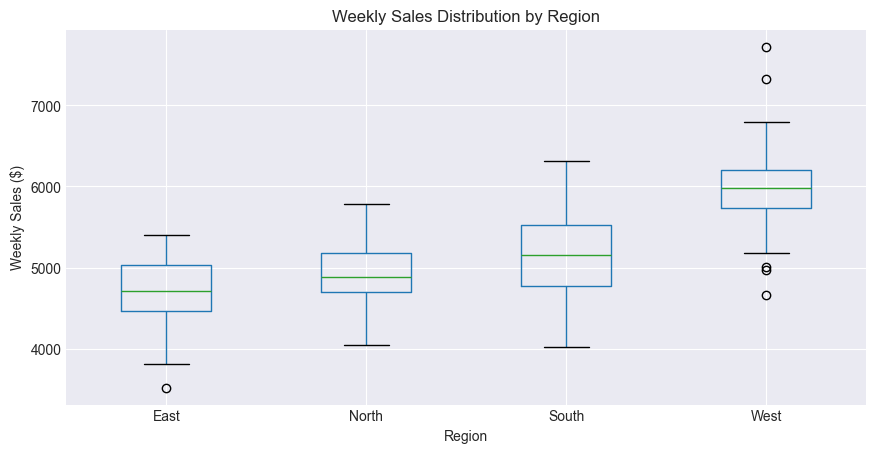

In [2]:
north = np.random.normal(loc=5000, scale=500, size=30)  # Average $5,000/week
south = np.random.normal(loc=5200, scale=600, size=30)  # Slightly higher
east  = np.random.normal(loc=4700, scale=450, size=30)  # Slightly lower
west  = np.random.normal(loc=6000, scale=700, size=30)  # Noticeably higher

# Build a single tidy DataFrame
df = pd.DataFrame({
    'Sales': np.concatenate([north, south, east, west]),
    'Region': ['North']*30 + ['South']*30 + ['East']*30 + ['West']*30
})

# Summary Statistics
print('=== SUMMARY STATISTICS PER REGION ===')
display(df.groupby('Region')['Sales'].agg(['mean', 'std', 'count']).round(2))

# Visualise the distributions with Box Plots
fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column='Sales', by='Region', ax=ax)
ax.set_title('Weekly Sales Distribution by Region')
ax.set_ylabel('Weekly Sales ($)')
plt.suptitle('')
plt.show()

### Step 2: Run the One-Way ANOVA Test
We use `scipy.stats.f_oneway()`. The output is the **F-statistic** and the **p-value**.

**Decision Rule:** If p-value < 0.05, reject H0 — at least one region is genuinely different.

In [3]:
f_stat, p_value = stats.f_oneway(north, south, east, west)

print(f'F-statistic: {f_stat:.4f}')
print(f'p-value:     {p_value:.6f}')

if p_value < 0.05:
    print('\nVerdict: REJECT H0 — At least one region has a significantly different mean sales!')
else:
    print('\nVerdict: FAIL to reject H0 — No significant difference found between regions.')

F-statistic: 34.0467
p-value:     0.000000

Verdict: REJECT H0 — At least one region has a significantly different mean sales!


### Step 3: Post-Hoc Test — Which regions are different? (Tukey's HSD)
ANOVA tells us SOMETHING is different. Tukey's HSD tells us WHICH specific pairs of regions are different, while controlling the false-positive rate.

In [4]:
tukey_result = pairwise_tukeyhsd(endog=df['Sales'], groups=df['Region'], alpha=0.05)
print(tukey_result)
print('\nNote: reject=True means those two regions ARE significantly different from each other.')

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
  East  North  200.1284 0.4615 -155.7857  556.0425  False
  East  South  421.5044 0.0133   65.5903  777.4184   True
  East   West 1280.0257    0.0  924.1116 1635.9398   True
 North  South   221.376 0.3707 -134.5381    577.29  False
 North   West 1079.8973    0.0  723.9832 1435.8114   True
 South   West  858.5213    0.0  502.6073 1214.4354   True
---------------------------------------------------------

Note: reject=True means those two regions ARE significantly different from each other.


---
# PART 2: Monte Carlo Simulation
## Business Problem
Your company is about to launch a new product. You need to answer: **'What is the probability that this product launch will be profitable?'**

You have 3 uncertain variables:
- **Units Sold:** You estimate between 8,000 and 15,000 units (uniformly distributed)
- **Selling Price per unit:** Approximately $50, but could vary ±$8 (normally distributed)
- **Cost per unit:** Approximately $30, but could vary ±$5 (normally distributed)

**Profit = (Price - Cost) × Units Sold**

### Step 1: Define the Number of Simulations
We run 50,000 trials. In each trial, we randomly draw from each variable's distribution.

In [ ]:
N_SIMULATIONS = 50000

# Randomly sample each uncertain variable
units_sold    = np.random.uniform(low=8000, high=15000, size=N_SIMULATIONS)
selling_price = np.random.normal(loc=50, scale=8, size=N_SIMULATIONS)
cost_per_unit = np.random.normal(loc=30, scale=5, size=N_SIMULATIONS)

# Calculate Profit for each of the 50,000 simulated scenarios
profit = (selling_price - cost_per_unit) * units_sold

print(f'Simulations completed: {N_SIMULATIONS:,}')
print(f'Average Profit:        ${np.mean(profit):,.0f}')
print(f'Worst-Case Profit:     ${np.min(profit):,.0f}')
print(f'Best-Case Profit:      ${np.max(profit):,.0f}')

### Step 2: Answer the Key Business Question
What is the probability of losing money (profit < 0)?

In [ ]:
prob_loss   = np.mean(profit < 0) * 100
prob_profit = np.mean(profit > 0) * 100
prob_100k   = np.mean(profit > 100000) * 100

print('=== PROBABILITY ANALYSIS ===')
print(f'Probability of LOSS:              {prob_loss:.2f}%')
print(f'Probability of PROFIT:            {prob_profit:.2f}%')
print(f'Probability of Profit > $100,000: {prob_100k:.2f}%')

### Step 3: Visualise the Profit Distribution
This histogram shows the full distribution of all 50,000 simulated profit outcomes.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

# Split into profit (green) and loss (red) for clarity
ax.hist(profit[profit >= 0], bins=80, color='#2ecc71', alpha=0.75, label='Profitable Scenarios')
ax.hist(profit[profit < 0],  bins=80, color='#e74c3c', alpha=0.75, label='Loss Scenarios')

# Mean and percentile lines
ax.axvline(np.mean(profit),              color='white',  linestyle='--', lw=2, label=f'Mean: ${np.mean(profit):,.0f}')
ax.axvline(np.percentile(profit, 5),     color='orange', linestyle=':',  lw=2, label=f'5th Pct (Worst 5%): ${np.percentile(profit, 5):,.0f}')
ax.axvline(np.percentile(profit, 95),    color='cyan',   linestyle=':',  lw=2, label=f'95th Pct (Best 5%): ${np.percentile(profit, 95):,.0f}')

ax.set_title('Monte Carlo Simulation: 50,000 Product Launch Profit Scenarios', fontsize=14, fontweight='bold')
ax.set_xlabel('Profit ($)', fontsize=12)
ax.set_ylabel('Frequency (Number of Simulations)', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print('\n=== FINAL RECOMMENDATION TO MANAGEMENT ===')
print(f'Based on 50,000 simulated scenarios:')
print(f'  - There is a {prob_profit:.1f}% chance this launch will be profitable.')
print(f'  - There is a {prob_loss:.1f}% chance of a loss.')
print(f'  - The expected (average) profit is ${np.mean(profit):,.0f}.')